
# Network Intrusion Detection using Machine Learning

**Dataset:** CIC-IDS2017  
**Task:** Binary classification — Benign vs Attack  
**Recommended models:** Logistic Regression, Random Forest, and Gradient Boosting

This notebook is designed for a university project. It covers data loading, exploration, cleaning, preprocessing, class distribution, model training, evaluation, confusion matrices, ROC curves, and feature importance.


In [5]:

# 1. Install/import required libraries
# If needed, run this cell once:
# !pip install pandas numpy matplotlib seaborn scikit-learn imbalanced-learn joblib

import os
import glob
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, roc_auc_score,
    roc_curve
)
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier


## 2. Load the CIC-IDS2017 CSV files

Download the CSV version of CIC-IDS2017 and place the files in a folder named `CICIDS2017` beside this notebook. The original dataset provides labeled network flows and more than 80 flow features.

In [9]:
DATA_DIR = r"C:\Users\User\Documents\CICIDS2017"

parquet_files = glob.glob(
    os.path.join(DATA_DIR, "**", "*.parquet"),
    recursive=True
)

print("Parquet files found:", len(parquet_files))

for f in parquet_files:
    print(f)


Parquet files found: 8
C:\Users\User\Documents\CICIDS2017\Benign-Monday-no-metadata.parquet
C:\Users\User\Documents\CICIDS2017\Botnet-Friday-no-metadata.parquet
C:\Users\User\Documents\CICIDS2017\Bruteforce-Tuesday-no-metadata.parquet
C:\Users\User\Documents\CICIDS2017\DDoS-Friday-no-metadata.parquet
C:\Users\User\Documents\CICIDS2017\DoS-Wednesday-no-metadata.parquet
C:\Users\User\Documents\CICIDS2017\Infiltration-Thursday-no-metadata.parquet
C:\Users\User\Documents\CICIDS2017\Portscan-Friday-no-metadata.parquet
C:\Users\User\Documents\CICIDS2017\WebAttacks-Thursday-no-metadata.parquet


In [10]:
# Load all CSV files
import pandas as pd

dfs = []

for file in parquet_files:
    try:
        temp = pd.read_parquet(file)

        # Clean column names
        temp.columns = temp.columns.str.strip()

        dfs.append(temp)

        print(f"Loaded: {os.path.basename(file)}")
        print(f"Shape: {temp.shape}\n")

    except Exception as e:
        print(f"Error loading {file}: {e}")

if not dfs:
    raise FileNotFoundError("No Parquet files were loaded.")

df = pd.concat(dfs, ignore_index=True)

print("Combined dataset shape:", df.shape)

df.head()


Loaded: Benign-Monday-no-metadata.parquet
Shape: (458831, 78)

Loaded: Botnet-Friday-no-metadata.parquet
Shape: (176038, 78)

Loaded: Bruteforce-Tuesday-no-metadata.parquet
Shape: (389714, 78)

Loaded: DDoS-Friday-no-metadata.parquet
Shape: (221264, 78)

Loaded: DoS-Wednesday-no-metadata.parquet
Shape: (584991, 78)

Loaded: Infiltration-Thursday-no-metadata.parquet
Shape: (207630, 78)

Loaded: Portscan-Friday-no-metadata.parquet
Shape: (119522, 78)

Loaded: WebAttacks-Thursday-no-metadata.parquet
Shape: (155820, 78)

Combined dataset shape: (2313810, 78)


,Protocol,Flow Duration,Total Fwd Packets,Total Backward Packets,Fwd Packets Length Total,Bwd Packets Length Total,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,...,Fwd Seg Size Min,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label
0,6,4,2,0,12,0,6,6,6.00000,0.000000,...,20,0.0,0.0,0,0,0.0,0.0,0,0,Benign
1,6,1,2,0,12,0,6,6,6.00000,0.000000,...,20,0.0,0.0,0,0,0.0,0.0,0,0,Benign
2,6,3,2,0,12,0,6,6,6.00000,0.000000,...,20,0.0,0.0,0,0,0.0,0.0,0,0,Benign
3,6,1,2,0,12,0,6,6,6.00000,0.000000,...,20,0.0,0.0,0,0,0.0,0.0,0,0,Benign
4,6,609,7,4,484,414,233,0,69.14286,111.967896,...,20,0.0,0.0,0,0,0.0,0.0,0,0,Benign


## 3. Inspect the dataset

In [11]:

print("Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

print("\nData types:")
display(df.dtypes.value_counts())

print("\nMissing values:")
display(df.isnull().sum().sort_values(ascending=False).head(20))


Shape: (2313810, 78)

Columns:
['Protocol', 'Flow Duration', 'Total Fwd Packets', 'Total Backward Packets', 'Fwd Packets Length Total', 'Bwd Packets Length Total', 'Fwd Packet Length Max', 'Fwd Packet Length Min', 'Fwd Packet Length Mean', 'Fwd Packet Length Std', 'Bwd Packet Length Max', 'Bwd Packet Length Min', 'Bwd Packet Length Mean', 'Bwd Packet Length Std', 'Flow Bytes/s', 'Flow Packets/s', 'Flow IAT Mean', 'Flow IAT Std', 'Flow IAT Max', 'Flow IAT Min', 'Fwd IAT Total', 'Fwd IAT Mean', 'Fwd IAT Std', 'Fwd IAT Max', 'Fwd IAT Min', 'Bwd IAT Total', 'Bwd IAT Mean', 'Bwd IAT Std', 'Bwd IAT Max', 'Bwd IAT Min', 'Fwd PSH Flags', 'Bwd PSH Flags', 'Fwd URG Flags', 'Bwd URG Flags', 'Fwd Header Length', 'Bwd Header Length', 'Fwd Packets/s', 'Bwd Packets/s', 'Packet Length Min', 'Packet Length Max', 'Packet Length Mean', 'Packet Length Std', 'Packet Length Variance', 'FIN Flag Count', 'SYN Flag Count', 'RST Flag Count', 'PSH Flag Count', 'ACK Flag Count', 'URG Flag Count', 'CWE Flag Count'

int32      26
float32    22
int8       19
int16       7
float64     2
int64       1
object      1
Name: count, dtype: int64


Missing values:


Protocol                  0
CWE Flag Count            0
Fwd Avg Packets/Bulk      0
Fwd Avg Bytes/Bulk        0
Avg Bwd Segment Size      0
Avg Fwd Segment Size      0
Avg Packet Size           0
Down/Up Ratio             0
ECE Flag Count            0
URG Flag Count            0
Bwd Avg Bytes/Bulk        0
ACK Flag Count            0
PSH Flag Count            0
RST Flag Count            0
SYN Flag Count            0
FIN Flag Count            0
Packet Length Variance    0
Packet Length Std         0
Fwd Avg Bulk Rate         0
Bwd Avg Packets/Bulk      0
dtype: int64

In [12]:

# Identify the label column
label_candidates = [c for c in df.columns if c.lower() in ["label", "attack", "attack_type", "attack type"]]
print("Possible label columns:", label_candidates)

if not label_candidates:
    raise ValueError("Could not automatically find the label column. Check df.columns.")

LABEL_COL = label_candidates[0]
print("Using label column:", LABEL_COL)

print(df[LABEL_COL].value_counts(dropna=False))


Possible label columns: ['Label']
Using label column: Label
Label
Benign                        1977318
DoS Hulk                       172846
DDoS                           128014
DoS GoldenEye                   10286
FTP-Patator                      5931
DoS slowloris                    5385
DoS Slowhttptest                 5228
SSH-Patator                      3219
PortScan                         1956
Web Attack � Brute Force         1470
Bot                              1437
Web Attack � XSS                  652
Infiltration                       36
Web Attack � Sql Injection         21
Heartbleed                         11
Name: count, dtype: int64


In [13]:
# 4. Clean column names and numeric values
df.columns = df.columns.str.strip()

# Replace infinite values
df = df.replace([np.inf, -np.inf], np.nan)

# Remove duplicate rows
before = len(df)
df = df.drop_duplicates()
print("Duplicates removed:", before - len(df))

# Remove rows without a label
df = df.dropna(subset=[LABEL_COL])

# Convert feature columns to numeric where possible
feature_cols = [c for c in df.columns if c != LABEL_COL]

for c in feature_cols:
    df[c] = pd.to_numeric(df[c], errors="coerce")

# Drop columns that became completely empty
empty_cols = [c for c in feature_cols if df[c].isna().all()]
df = df.drop(columns=empty_cols)

print("Cleaned shape:", df.shape)


Duplicates removed: 82004
Cleaned shape: (2231806, 78)


## 5. Convert labels to binary classes

For a simple and strong project setup, every benign label becomes `0`, while every attack label becomes `1`.

In [14]:

df["target"] = (
    df[LABEL_COL]
    .astype(str)
    .str.strip()
    .str.lower()
    .apply(lambda x: 0 if "benign" in x or "normal" in x else 1)
)

print(df["target"].value_counts())
print("\n0 = Benign")
print("1 = Attack")


target
0    1895314
1     336492
Name: count, dtype: int64

0 = Benign
1 = Attack


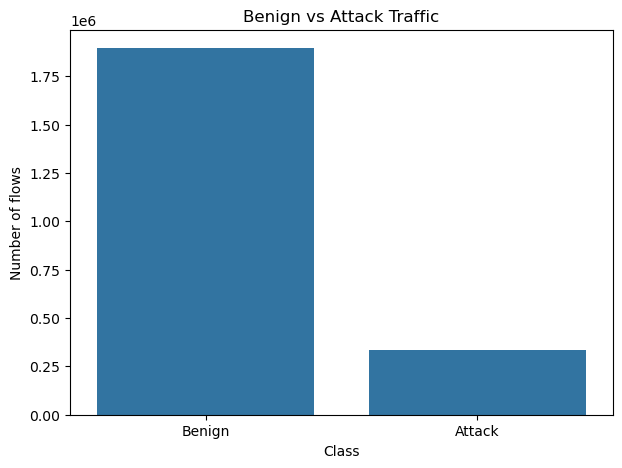

In [15]:

plt.figure(figsize=(7, 5))
sns.countplot(x="target", data=df)
plt.title("Benign vs Attack Traffic")
plt.xlabel("Class")
plt.ylabel("Number of flows")
plt.xticks([0, 1], ["Benign", "Attack"])
plt.show()


## 6. Prepare features and target

In [16]:

X = df.drop(columns=[LABEL_COL, "target"], errors="ignore")
y = df["target"]

# Keep numeric columns only
X = X.select_dtypes(include=[np.number])

# Replace inf and missing values
X = X.replace([np.inf, -np.inf], np.nan)

# Remove columns with too many missing values
missing_ratio = X.isna().mean()
X = X.loc[:, missing_ratio < 0.50]

print("Final feature shape:", X.shape)
print("Target shape:", y.shape)


Final feature shape: (2231806, 77)
Target shape: (2231806,)


In [17]:

# Train/test split with stratification
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape)
print("Testing samples:", X_test.shape)


Training samples: (1785444, 77)
Testing samples: (446362, 77)


## 7. Train Logistic Regression

This provides a baseline model.

In [18]:

lr_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=1000, class_weight="balanced"))
])

lr_pipeline.fit(X_train, y_train)
lr_pred = lr_pipeline.predict(X_test)
lr_prob = lr_pipeline.predict_proba(X_test)[:, 1]

print(classification_report(y_test, lr_pred, target_names=["Benign", "Attack"]))
print("ROC-AUC:", roc_auc_score(y_test, lr_prob))


              precision    recall  f1-score   support

      Benign       0.99      0.94      0.97    379063
      Attack       0.75      0.97      0.84     67299

    accuracy                           0.95    446362
   macro avg       0.87      0.96      0.91    446362
weighted avg       0.96      0.95      0.95    446362

ROC-AUC: 0.9929987262866855


## 8. Train Random Forest

In [19]:

rf_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", RandomForestClassifier(
        n_estimators=150,
        random_state=42,
        n_jobs=-1,
        class_weight="balanced"
    ))
])

rf_pipeline.fit(X_train, y_train)
rf_pred = rf_pipeline.predict(X_test)
rf_prob = rf_pipeline.predict_proba(X_test)[:, 1]

print(classification_report(y_test, rf_pred, target_names=["Benign", "Attack"]))
print("ROC-AUC:", roc_auc_score(y_test, rf_prob))


              precision    recall  f1-score   support

      Benign       1.00      1.00      1.00    379063
      Attack       1.00      1.00      1.00     67299

    accuracy                           1.00    446362
   macro avg       1.00      1.00      1.00    446362
weighted avg       1.00      1.00      1.00    446362

ROC-AUC: 0.9999221837374457


## 9. Train Gradient Boosting

In [22]:
gb_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", GradientBoostingClassifier(
        n_estimators=100,
        random_state=42
    ))
])

gb_pipeline.fit(X_train, y_train)
gb_pred = gb_pipeline.predict(X_test)
gb_prob = gb_pipeline.predict_proba(X_test)[:, 1]

print(classification_report(y_test, gb_pred, target_names=["Benign", "Attack"]))
print("ROC-AUC:", roc_auc_score(y_test, gb_prob))

              precision    recall  f1-score   support

      Benign       1.00      1.00      1.00    379063
      Attack       0.99      0.98      0.99     67299

    accuracy                           1.00    446362
   macro avg       1.00      0.99      0.99    446362
weighted avg       1.00      1.00      1.00    446362

ROC-AUC: 0.9994881508061139


## 10. Compare the models

In [ ]:
def model_metrics(name, y_true, y_pred, y_prob):
    return {
        "Model": name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1 Score": f1_score(y_true, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_true, y_prob)
    }

results = pd.DataFrame([
    model_metrics("Logistic Regression", y_test, lr_pred, lr_prob),
    model_metrics("Random Forest", y_test, rf_pred, rf_prob),
    model_metrics("Gradient Boosting", y_test, gb_pred, gb_prob)
])

results.sort_values("F1 Score", ascending=False)


In [ ]:
results.set_index("Model")[["Accuracy", "Precision", "Recall", "F1 Score", "ROC-AUC"]].plot(
    kind="bar", figsize=(12, 6)
)
plt.title("Model Performance Comparison")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.show()


## 11. Confusion matrices

In [ ]:
predictions = {
    "Logistic Regression": lr_pred,
    "Random Forest": rf_pred,
    "Gradient Boosting": gb_pred
}

for name, pred in predictions.items():
    cm = confusion_matrix(y_test, pred)
    plt.figure(figsize=(5, 4))
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues",
        xticklabels=["Benign", "Attack"],
        yticklabels=["Benign", "Attack"]
    )
    plt.title(f"Confusion Matrix - {name}")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.show()


## 12. ROC curves

In [ ]:
plt.figure(figsize=(9, 6))

for name, prob in [
    ("Logistic Regression", lr_prob),
    ("Random Forest", rf_prob),
    ("Gradient Boosting", gb_prob)
]:
    fpr, tpr, _ = roc_curve(y_test, prob)
    auc = roc_auc_score(y_test, prob)
    plt.plot(fpr, tpr, label=f"{name} (AUC={auc:.4f})")

plt.plot([0, 1], [0, 1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")
plt.legend()
plt.show()


## 13. Random Forest feature importance

In [ ]:
rf_model = rf_pipeline.named_steps["model"]

importance = pd.Series(
    rf_model.feature_importances_,
    index=X_train.columns
).sort_values(ascending=False)

plt.figure(figsize=(10, 8))
importance.head(20).sort_values().plot(kind="barh")
plt.title("Top 20 Important Network Features")
plt.xlabel("Importance")
plt.show()

display(importance.head(20).to_frame("Importance"))


## 14. Save the best model

In [ ]:
import joblib

best_name = results.sort_values("F1 Score", ascending=False).iloc[0]["Model"]

models = {
    "Logistic Regression": lr_pipeline,
    "Random Forest": rf_pipeline,
    "Gradient Boosting": gb_pipeline
}

best_model = models[best_name]
joblib.dump(best_model, "network_intrusion_detection_model.pkl")

print("Best model:", best_name)
print("Saved as: network_intrusion_detection_model.pkl")



## 15. Project conclusion

The system classifies network flows into **Benign** and **Attack** traffic using machine learning. The models are evaluated using accuracy, precision, recall, F1-score, ROC-AUC, confusion matrices, and ROC curves.
